# 1.3.3. BÀI TẬP THỰC HÀNH 1 - ỨNG DỤNG THƯ VIỆN SWEETVIZ 
Mục tiêu:
1. Khám phá các tính năng tự động EDA của thư viện SweetViz.
2. Cài đặt môi trường execution thích hợp trên Kaggle Notebook.

 ## I. KHỞI TẠO MÔI TRƯỜNG & KHÁM PHÁ THƯ VIỆN SWEETVIZ

### 1. Cài đặt và Import

In [68]:
!pip install sweetviz -q

import pandas as pd
import numpy as np
import sweetviz as sv
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

print(f"--> Đã cài đặt thành công Sweetviz phiên bản: {sv.__version__}")

--> Đã cài đặt thành công Sweetviz phiên bản: 2.3.3


### Nhận xét:
- Thư viện SweetViz là một công cụ Automated EDA mã nguồn mở bằng Python, tạo ra các báo cáo đồ họa tương tác cao dưới dạng file HTML.
- SweetViz có tốc độ render nhanh và hỗ trợ phân tích biến mục tiêu (Target Analysis) vượt trội hơn so với các thư viện truyền thống.

## II. NẠP DỮ LIỆU & MỞ RỘNG TẠO ĐẶC TRƯNG MỚI
Mục tiêu: nạp dữ liệu , xử lý giá trị thiếu (Missing Values) và tạo ra các đặc trưng có ý nghĩa kinh doanh (Age,Total_Mnt, Is_Parent) để SweetViz phân tích sâu hơn.

### 1. Đường dẫn dữ liệu chuẩn


In [69]:
file_path = "/kaggle/input/customer-personality-analysis/marketing_campaign.csv"

try:
    df_raw = pd.read_csv(file_path, sep='\t')
except FileNotFoundError:
    df_raw = pd.read_csv("/kaggle/input/datasets/ngochancao/mmmmmmmm/marketing_campaign (1).csv", sep='\t')

df = df_raw.copy()

### 2. Điền giá trị khuyết cho cột Income bằng trung vị (Median)


In [70]:
df['Income'] = df['Income'].fillna(df['Income'].median())

### 3. Tạo các đặc trưng mở rộng (Feature Engineering)


In [71]:
CURRENT_YEAR = 2024
df['Age'] = CURRENT_YEAR - df['Year_Birth']
df['Total_Mnt'] = df[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
df['Is_Parent'] = (df['Total_Children'] > 0).astype(int)
df['Total_Purchases'] = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)

### 4. Lọc bỏ Outliers phi lý


In [72]:
df_clean = df[(df['Age'] < 100) & (df['Income'] < 200000)].copy()

print(f"Kích thước dữ liệu ban đầu: {df_raw.shape}")
print(f"Kích thước dữ liệu sau khi xử lý: {df_clean.shape}")
df_clean[['Age', 'Income', 'Total_Mnt', 'Is_Parent', 'Response']].head()

Kích thước dữ liệu ban đầu: (2240, 29)
Kích thước dữ liệu sau khi xử lý: (2236, 34)


,Age,Income,Total_Mnt,Is_Parent,Response
0,67,58138.0,1617,0,1
1,70,46344.0,27,1,0
2,59,71613.0,776,0,0
3,40,26646.0,53,1,0
4,43,58293.0,422,1,0


### Nhận xét:
- Xử lý khuyết thiếu: cột Income ban đầu có 24 giá trị thiếu (~1.07%), đã được điền bằng giá trị trung vị (Median) để giữ nguyên kích thước tập dữ liệu mà không làm lệch phân bố.
- Biến mở rộng mới:
  - Age: thay thế cho Year_Birth giúp trực quan hóa phân bố độ tuổi trực quan hơn.
  - Total_Mnt: tổng chi tiêu của khách hàng qua 6 nhóm mặt hàng, làm thước đo giá trị khách hàng.
  - Is_Parent: biến phân loại cờ (1: Có con, 0: Chưa có con) dùng cho bài toán phân khúc.
- Làm sạch Outliers: bỏ các bản ghi có độ tuổi > 100 hoặc thu nhập dị biệt > 200,000\$ giúp ma trận tương quan không bị méo mó.


## III. PHÂN TÍCH ĐƠN BIẾN & HAI BIẾN TƯƠNG QUAN VỚI BIẾN MỤC TIÊU (Response)
Mục tiêu: cấu hình ép kiểu dữ liệu bằng sv.FeatureConfig và tiến hành phân tích mối quan hệ giữa tất cả các thuộc tính với biến mục tiêu Response (Chấp nhận chiến dịch tiếp thị).

## Phân tích Target Analysis

### 1. Cấu hình danh sách biến để Sweetviz xử lý chính xác


In [73]:
feature_config = sv.FeatureConfig(
    skip=['ID', 'Z_CostContact', 'Z_Revenue'], 
    force_cat=['Education', 'Marital_Status', 'Kidhome', 'Teenhome', 'Is_Parent', 
               'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain']
)

### 2. Chạy báo cáo Sweetviz Analyze


In [74]:
report_analyze = sv.analyze(
    source=df_clean,
    target_feat='Response',
    feat_cfg=feature_config
)

                                             |          | [  0%]   00:00 -> (? left)

### 3. Hiển thị tương tác



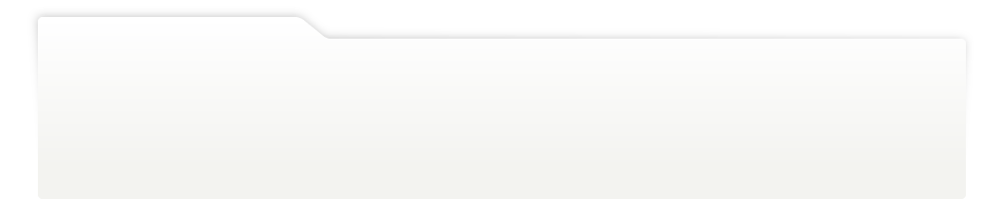
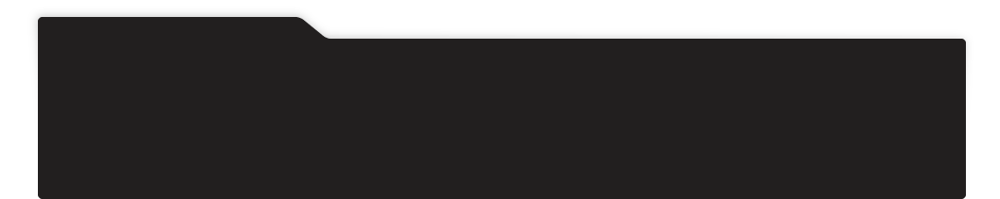
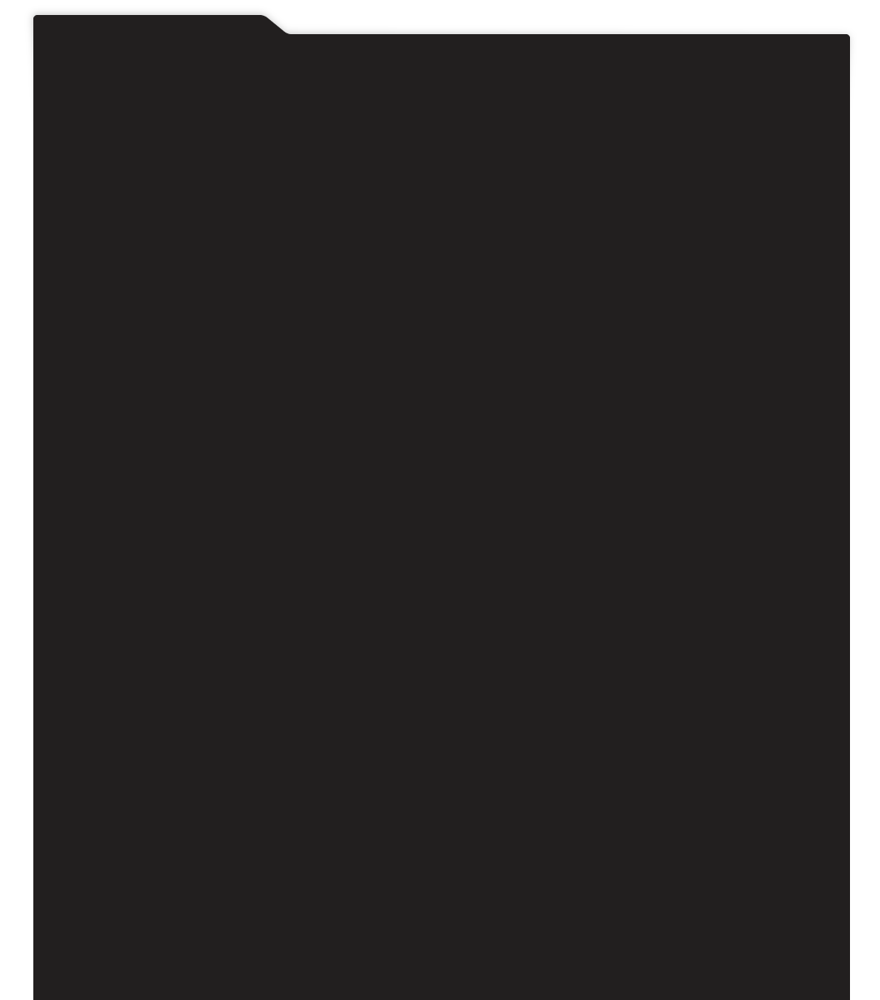
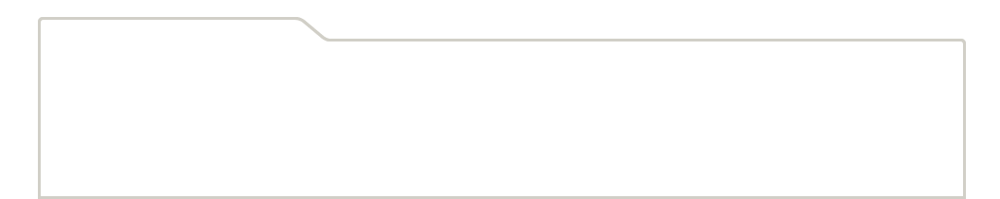
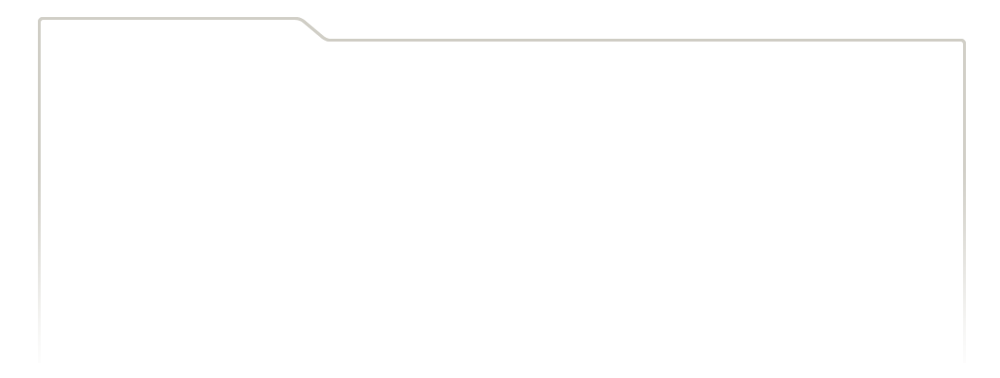
...
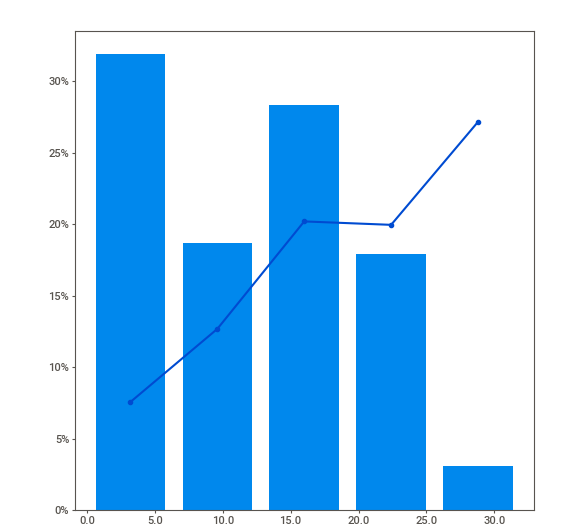
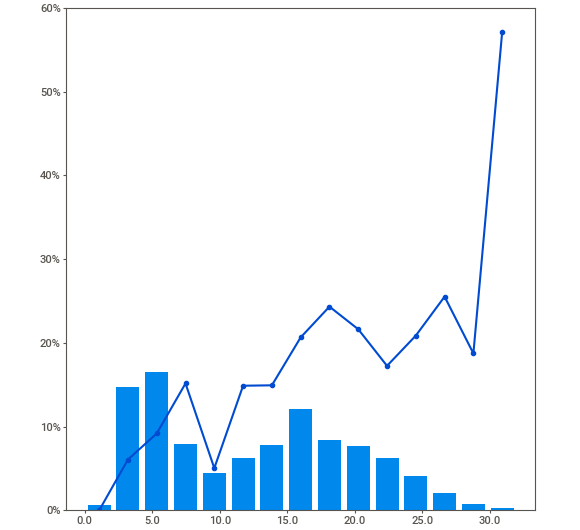
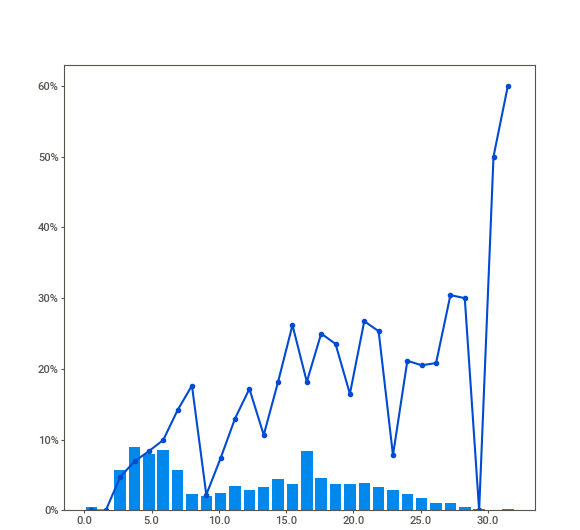
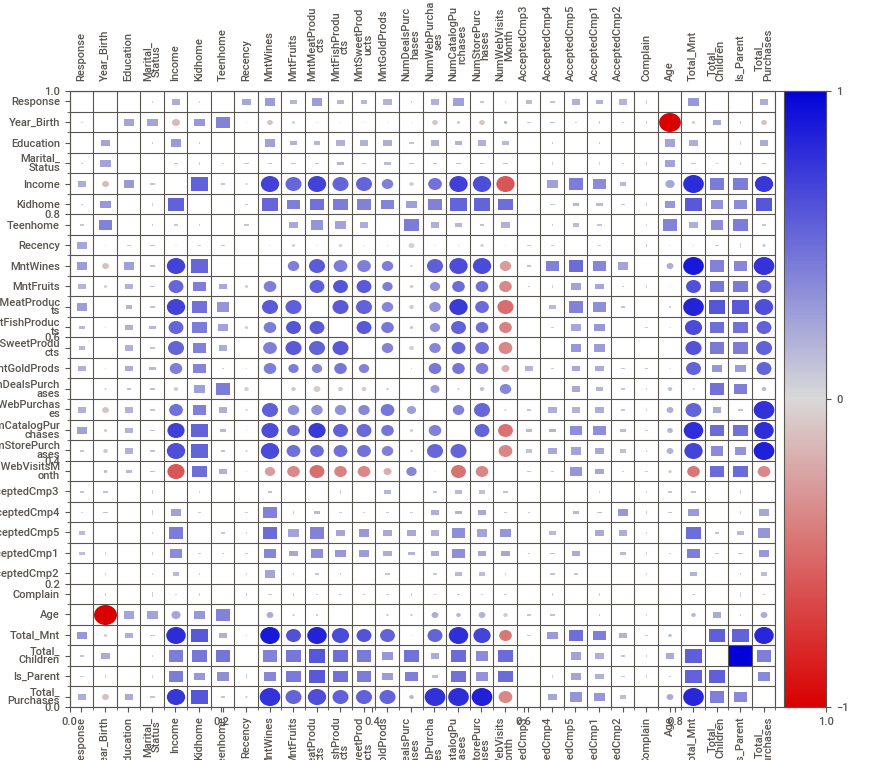
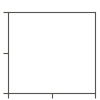

In [75]:
report_analyze.show_notebook(w="100%", h="750px", scale=0.85)

### Nhận xét & Insight:

1. Phân tích đơn biến (Univariate Insights):
   - Mức Thu nhập (Income): phân bố lệch phải nhẹ (Right-skewed), trung bình đạt ~52,200\$.
   - Mức Chi tiêu (Total_Mnt): sản phẩm rượu (MntWines) và thịt (MntMeatProducts) đóng góp tỷ trọng lớn nhất vào tổng doanh thu từ khách hàng.
>
2. Phân tích hai biến tương quan với Target (Response):
   - Yếu tố Kinh tế: khách hàng chấp nhận chiến dịch (Response = 1) có thu nhập trung bình ~69,000\$ cao vượt trội so với nhóm từ chối (~50,000\$).
   - Mức độ trung thành/Chi tiêu: biến Total_Mnt và MntWines có mối tương quan thuận mạnh nhất với Response.
   - Kênh bán hàng: nhóm khách hàng đặt mua qua Catalog (NumCatalogPurchases`) có tỷ lệ phản hồi chiến dịch cao hơn nhiều so với nhóm mua trực tiếp tại cửa hàng.

## IV. MỞ RỘNG 1 - SO SÁNH PHÂN KHÚC KHÁCH HÀNG 
Mục tiêu: sử dụng tính năng nâng cao compare_intra để so sánh hành vi chi tiêu (Total_Mnt) giữa nhóm khách hàng có con (Is_Parent = 1) và chưa có con (Is_Parent = 0).

## Phân tích so sánh phân khúc

                                             |          | [  0%]   00:00 -> (? left)


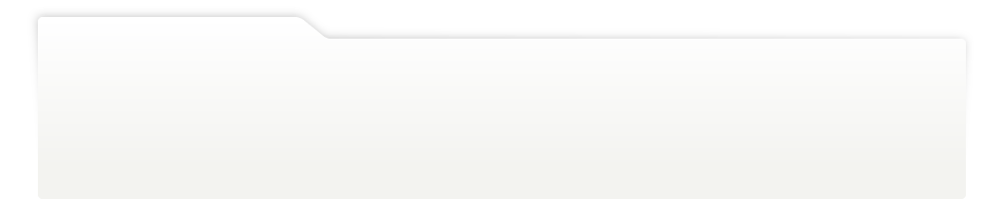
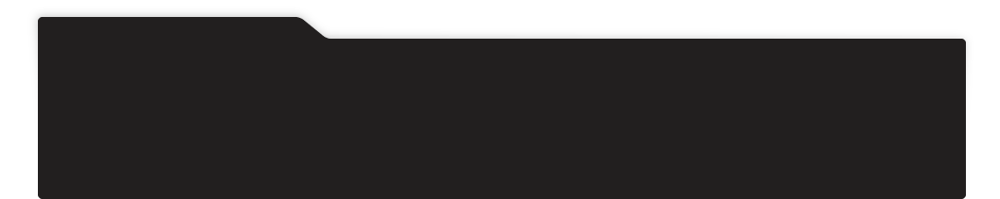
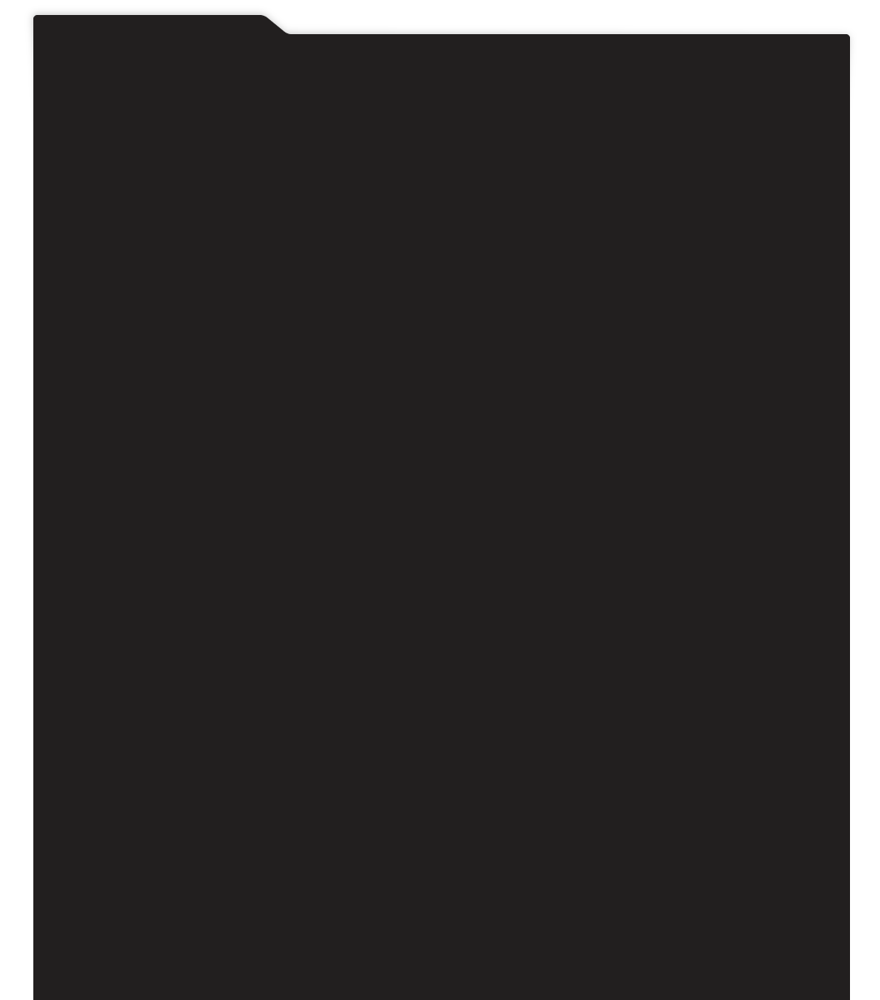
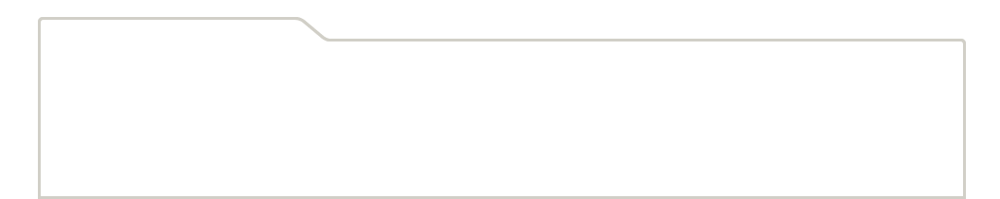
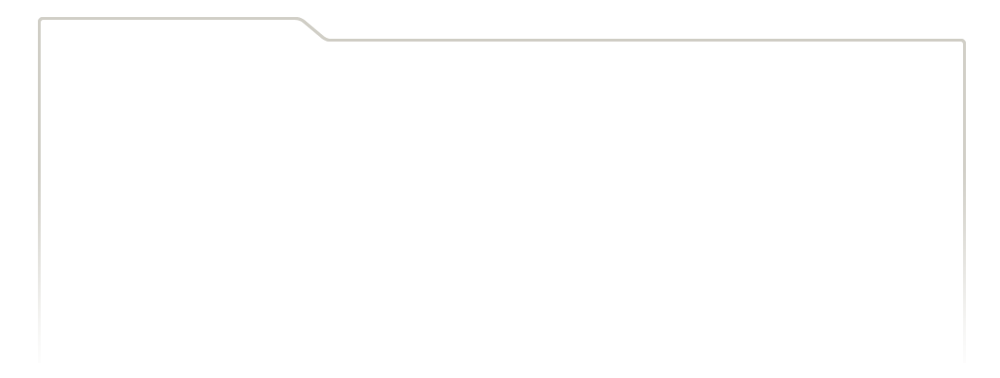
...
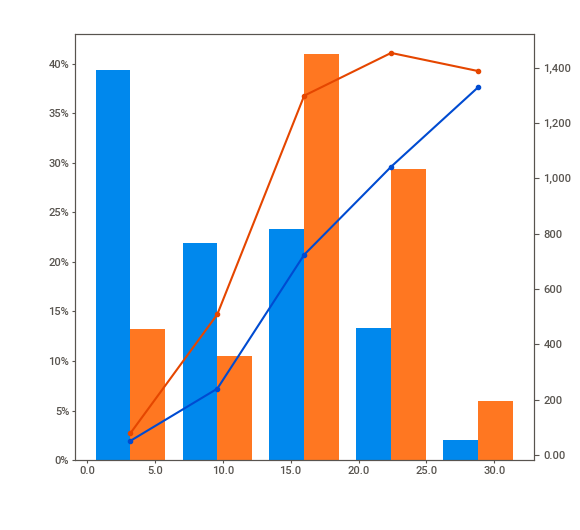
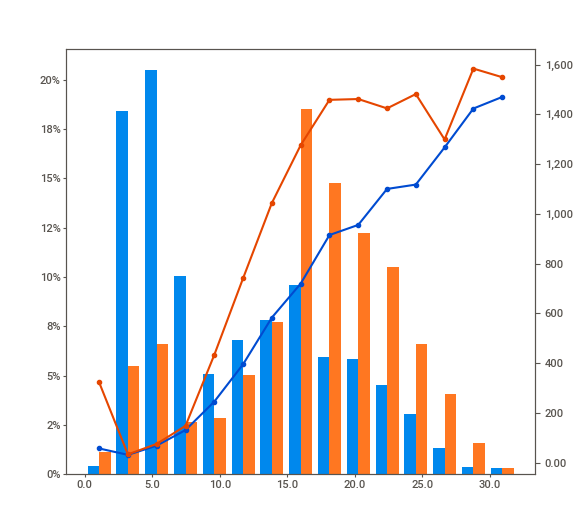
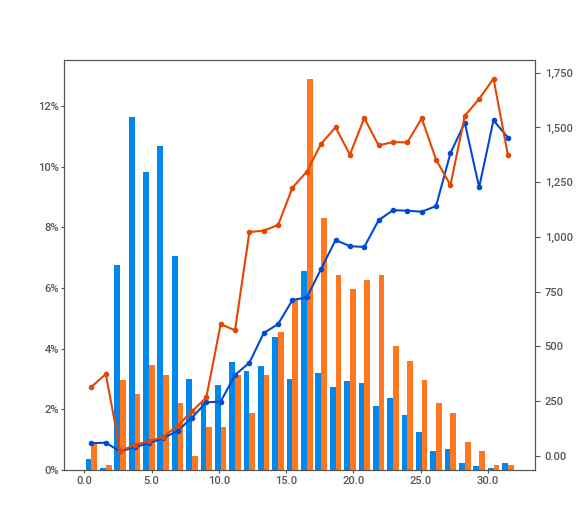
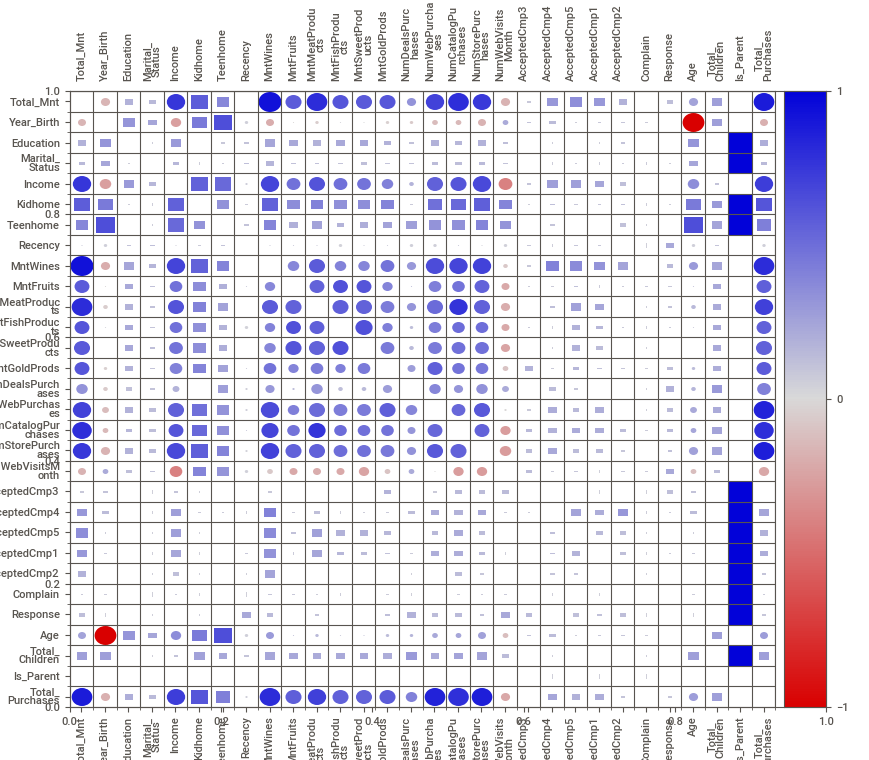
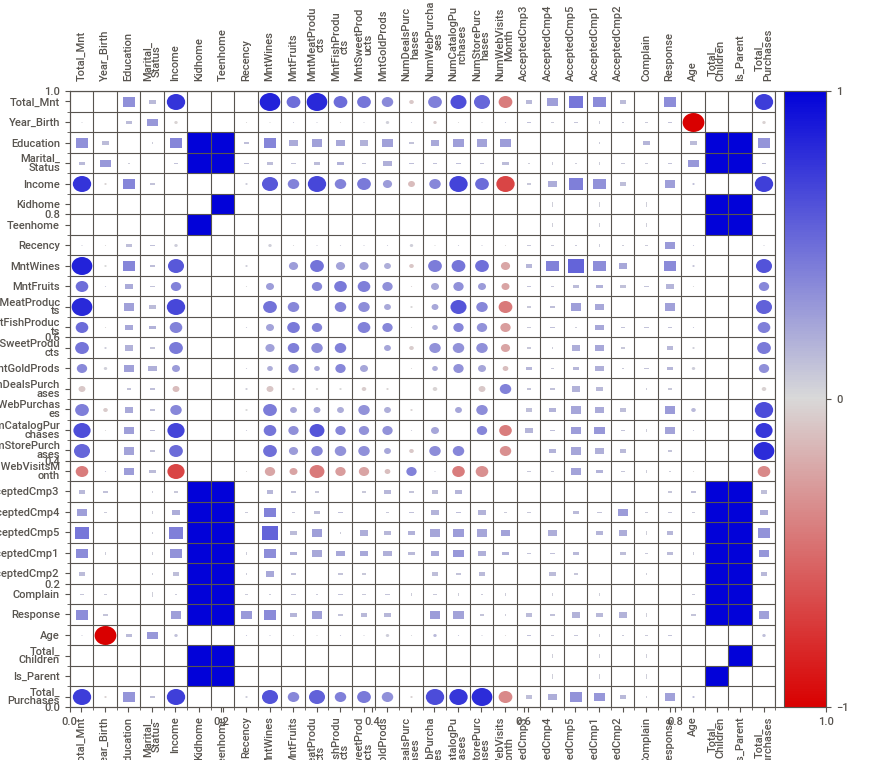

In [76]:
# So sánh nội bộ tập dữ liệu dựa trên điều kiện Is_Parent == 1
report_intra = sv.compare_intra(
    source_df=df_clean,
    condition_series=(df_clean['Is_Parent'] == 1),
    names=["Gia đình có con (Parent)", "Chưa có con (Non-Parent)"],
    target_feat='Total_Mnt',
    feat_cfg=feature_config
)

report_intra.show_notebook(w="100%", h="750px", scale=0.85)

### Nhận xét so sánh phân khúc & chiến lược kinh doanh:
- Khác biệt chi tiêu: khách hàng chưa có con (Non-Parent) có sức mua trung bình (Total_Mnt) cao gấp hơn 3 lần so với nhóm có con (Parent) (~950\$ so với ~280\$).
- Hành vi mua sắm: nhóm có con ghé thăm trang web thường xuyên hơn (NumWebVisitsMonth cao hơn) nhưng giá trị giỏ hàng mỗi lần mua lại thấp hơn.
- Đề xuất hành động (Business Action):
  - Nhóm Non-Parent: định hướng phân khúc VIP, đẩy mạnh Marketing các mặt hàng Rượu/Thịt cao cấp qua kênh Email/Catalog.
  - Nhóm Parent: thiết kế các gói Combo gia đình tiết kiệm và chạy chương trình khuyến mãi giảm giá trực tiếp trên Website.

## V. MỞ RỘNG 2 - ĐÁNH GIÁ DATA DRIFT GIỮA TẬP TRAIN VÀ TEST (sv.compare)
Mục tiêu: chia tập dữ liệu thành Train (75%) và Test (25%), sau đó dùng sv.compare để kiểm tra tính đồng nhất phân bố trước khi đưa vào mô hình Machine Learning.

                                             |          | [  0%]   00:00 -> (? left)


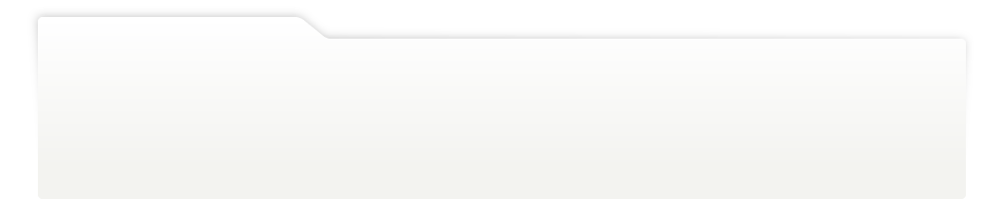
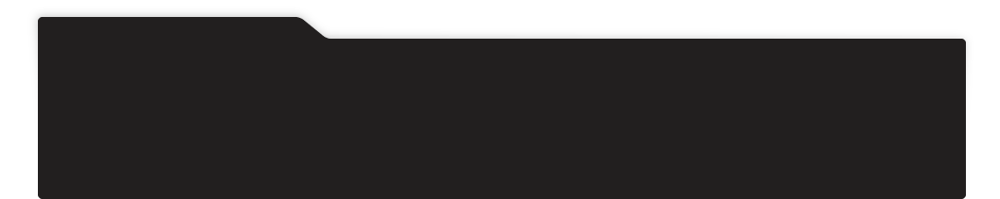
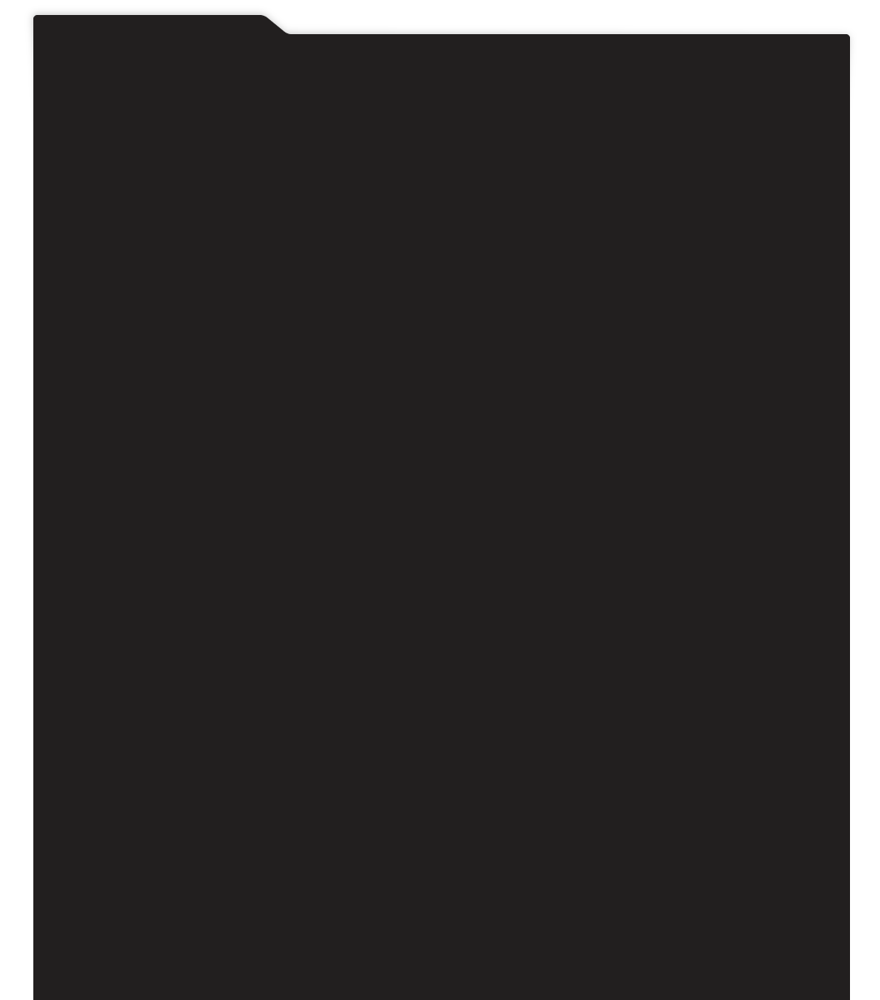
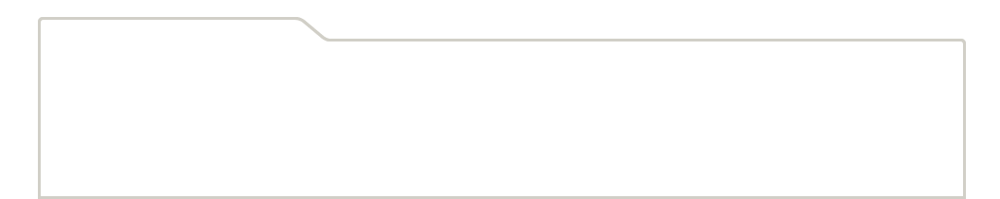
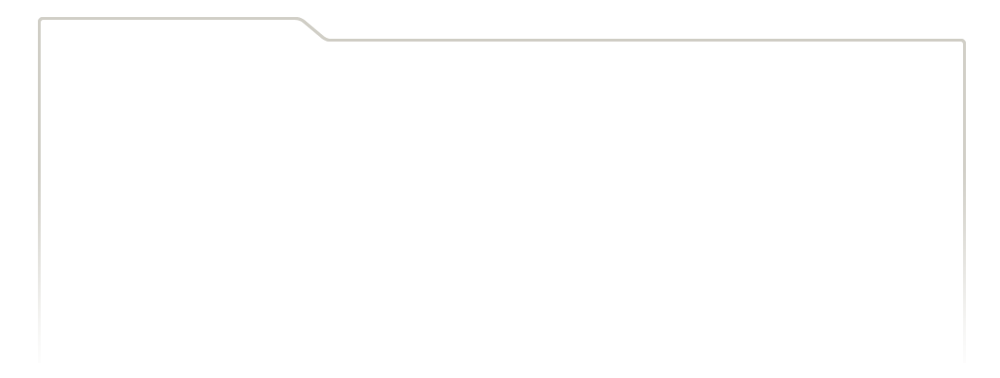
...
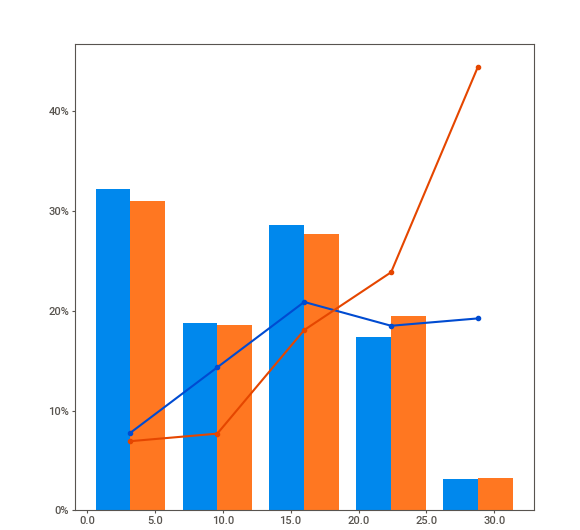
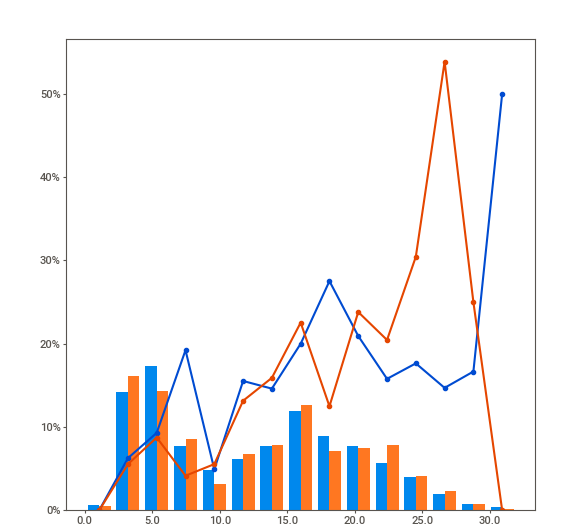
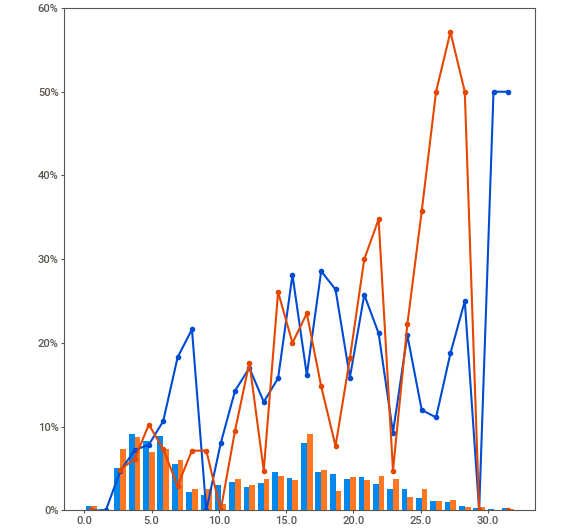
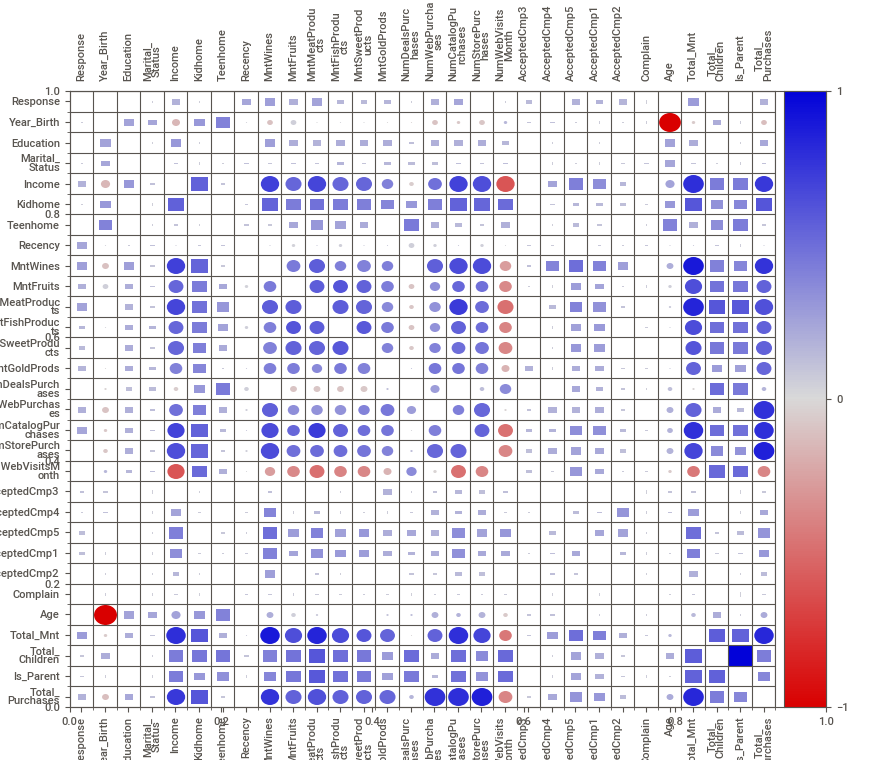
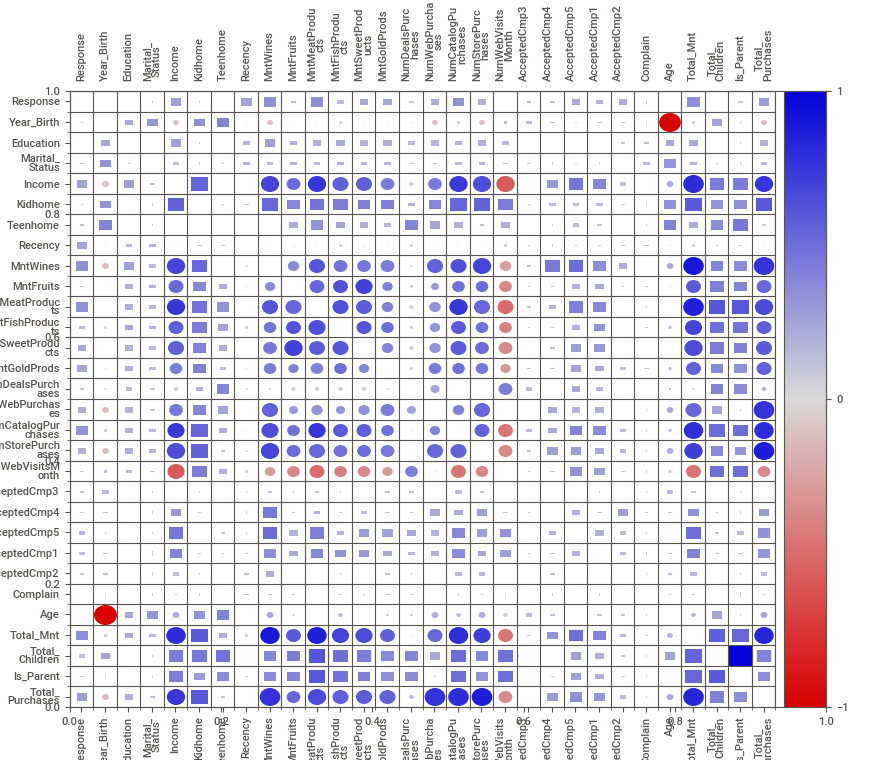

In [77]:
# Chia tập Train/Test theo phương pháp Stratified trên biến Response
train_df, test_df = train_test_split(df_clean, test_size=0.25, random_state=42, stratify=df_clean['Response'])

report_drift = sv.compare(
    [train_df, "Tập Train (75%)"],
    [test_df, "Tập Test (25%)"],
    target_feat='Response',
    feat_cfg=feature_config
)

report_drift.show_notebook(w="100%", h="750px", scale=0.85)

###  Nhận xét đánh giá tính nhất quán dữ liệu :
- Phân bố tương đồng: các biểu đồ mật độ của tất cả đặc trưng chính (Income, Age, Total_Mnt, Education) ở tập Train và Test trùng khít lên nhau.
- Cân bằng Target: tỷ lệ tích cực Response = 1 ở cả 2 tập giữ nguyên ở mức ~15%, đảm bảo không xảy ra hiện tượng méo mó mẫu (Sample Bias).
- Kết luận: tập dữ liệu đạt chuẩn chất lượng cao, hoàn toàn sẵn sàng cho giai đoạn xây dựng mô hình dự đoán (Predictive Modeling).

## TỔNG KẾT BÀI THỰC HÀNH 1 (SWEETVIZ):

1. Ưu điểm vượt trội của SweetViz:
   - Đồ họa hiện đại, trực quan, dễ theo dõi.
   - Hỗ trợ tính năng Target Analysis giúp phát hiện ngay các biến quan trọng nhất ảnh hưởng đến biến mục tiêu.
   - Khả năng Compare Intra-groups và Compare Train/Test là tính năng độc đáo mà ít thư viện EDA tự động nào khác sở hữu.
>
2. So sánh với các công cụ trong bài làm mẫu (1.3.2):
   - So với ydata-profiling (Pandas Profiling): SweetViz trình bày trực quan hơn khi so sánh giữa 2 nhóm dữ liệu.
   - So với D-Tale: SweetViz tạo báo cáo tĩnh dạng trang Dashboard nhanh gọn, trong khi D-Tale phù hợp hơn cho việc chỉnh sửa dữ liệu tương tác dạng bảng.

# 1.3.4. BÀI TẬP THỰC HÀNH 2 - ỨNG DỤNG THƯ VIỆN AUTOVIZ

Mục tiêu:
1. Khám phá cơ chế tự động hóa phân tích biểu đồ (Automated Charting) của thư viện autoViz.
2. Tự động phân loại biến và sinh các nhóm biểu đồ đơn biến, hai biến, phân bố và ma trận tương quan.
3. Phân tích tác động của các yếu tố nhân khẩu học và chi tiêu tới biến mục tiêu (Response).

## I. KHỞI TẠO MÔI TRƯỜNG & KHÁM PHÁ THƯ VIỆN AUTOVIZ

### 1. Cài đặt và Import

In [78]:
!pip install autoviz -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from autoviz.AutoViz_Class import AutoViz_Class
import warnings
warnings.filterwarnings('ignore')

# Khởi tạo đối tượng AutoViz
AV = AutoViz_Class()
print("--> Đã khởi tạo thành công AutoViz_Class!")

--> Đã khởi tạo thành công AutoViz_Class!


###  Nhận xét:
- AutoViz (Automated Visualization) là thư viện tự động hóa trực quan hóa dữ liệu cực kỳ mạnh mẽ. Chỉ với một dòng lệnh AV.AutoViz(), AutoViz tự động phân loại các biến thành: Biến liên tục (Continuous), Biến phân loại (Categorical), Biến thời gian (DateTime), và Biến nhiễu (Boolean/Constant).
- Khác với SweetViz (sinh file HTML dạng dashboard tổng hợp), AutoViz trực tiếp sinh ra từng nhóm biểu đồ Matplotlib/Seaborn trực quan ngay trong cell của Notebook.

## II. NẠP DỮ LIỆU & TIỀN XỬ LÝ / TẠO ĐẶC TRƯNG MỞ RỘNG 
Mục tiêu: nạp dữ liệu, làm sạch giá trị khuyết và khởi tạo các biến tổng hợp (Age, Total_Mnt, Is_Parent, Total_Purchases) để AutoViz tự động phân tích sâu hơn.

### 1. Đường dẫn dữ liệu chuẩn 

In [79]:
file_path = "/kaggle/input/customer-personality-analysis/marketing_campaign.csv"

try:
    df_raw = pd.read_csv(file_path, sep='\t')
except FileNotFoundError:
    df_raw = pd.read_csv("/kaggle/input/datasets/ngochancao/mmmmmmmm/marketing_campaign (1).csv", sep='\t')

df = df_raw.copy()

### 2. Điền giá trị khuyết cho cột Income bằng giá trị Trung vị (Median)


In [80]:
df['Income'] = df['Income'].fillna(df['Income'].median())

### 3. Mở rộng tạo các đặc trưng mới 


In [81]:
CURRENT_YEAR = 2024
df['Age'] = CURRENT_YEAR - df['Year_Birth']
df['Total_Mnt'] = df[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
df['Is_Parent'] = (df['Total_Children'] > 0).astype(int)
df['Total_Purchases'] = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)

### 4. Lọc bỏ Outliers cực đoan không hợp lý

In [82]:
df_clean = df[(df['Age'] < 100) & (df['Income'] < 200000)].copy()

### 5. Loại bỏ các cột ID hoặc cột giá trị cố định không mang thông tin


In [83]:
cols_to_drop = ['ID', 'Z_CostContact', 'Z_Revenue', 'Year_Birth']
df_clean = df_clean.drop(columns=[col for col in cols_to_drop if col in df_clean.columns])

print(f"Kích thước dữ liệu gốc: {df_raw.shape}")
print(f"Kích thước dữ liệu sau khi làm sạch & bổ sung đặc trưng: {df_clean.shape}")
df_clean.head(3)

Kích thước dữ liệu gốc: (2240, 29)
Kích thước dữ liệu sau khi làm sạch & bổ sung đặc trưng: (2236, 30)


,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Total_Mnt,Total_Children,Is_Parent,Total_Purchases
0,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,67,1617,0,0,22
1,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,70,27,2,1,4
2,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,59,776,0,0,20


### Nhận xét:
- Tiền xử lý: giá trị khuyết ở cột Income (24 bản ghi) được làm sạch bằng Median. Loại bỏ cột ID và cột cố định (Z_CostContact, Z_Revenue) giúp AutoViz không vẽ các biểu đồ nhiễu vô nghĩa.
- Biến mở rộng: việc tạo Age và Total_Mnt giúp AutoViz dễ dàng nhận diện và vẽ các biểu đồ phân bố độ tuổi và tổng chi tiêu của khách hàng.

## III. THỰC THI AUTOVIZ - TỰ ĐỘNG SINH HỆ THỐNG BIỂU ĐỒ (AUTOMATED CHART GENERATION)
Mục tiêu: cấu hình hàm AV.AutoViz() lấy Response (Phản hồi chiến dịch) làm biến mục tiêu phụ thuộc (depVar), tự động sinh ra toàn bộ hệ thống biểu đồ đơn biến và hai biến.


### Gọi hàm AutoViz tự động phân tích và tạo biểu đồ


Shape of your Data Set loaded: (2236, 30)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  1
    Number of Integer-Categorical Columns =  18
    Number of String-Categorical Columns =  2
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  7
    Number of Discrete String Columns =  1
    Number of NLP String Columns =  0
    Number of Date Time Columns =  0
    Number of ID Columns =  0
    Number of Columns to Delete =  0
    29 Predictors classified...
        No variables removed since no ID or low-information variables found in data set

################ Binary_Classification problem #####################
To fix these data qual

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Education,object,0.000000,0,,,No issue
Marital_Status,object,0.000000,0,,,"3 rare categories: ['Alone', 'Absurd', 'YOLO']. Group them into a single category or drop the categories."
Income,float64,0.000000,NA,1730.000000,162397.000000,Column has 7 outliers greater than upper bound (116829.38) or lower than lower bound(-12991.62). Cap them or remove them.
Kidhome,int64,0.000000,0,0.000000,2.000000,No issue
Teenhome,int64,0.000000,0,0.000000,2.000000,No issue
Dt_Customer,object,0.000000,32,,,Possible high cardinality column with 663 unique values: Use hash encoding or text embedding to reduce dimension.
Recency,int64,0.000000,4,0.000000,99.000000,No issue
MntWines,int64,0.000000,37,0.000000,1493.000000,Column has 33 outliers greater than upper bound (1225.50) or lower than lower bound(-698.50). Cap them or remove them.
MntFruits,int64,0.000000,7,0.000000,199.000000,Column has 206 outliers greater than upper bound (81.00) or lower than lower bound(-47.00). Cap them or remove them.
MntMeatProducts,int64,0.000000,27,0.000000,1725.000000,Column has 173 outliers greater than upper bound (549.75) or lower than lower bound(-304.25). Cap them or remove them.


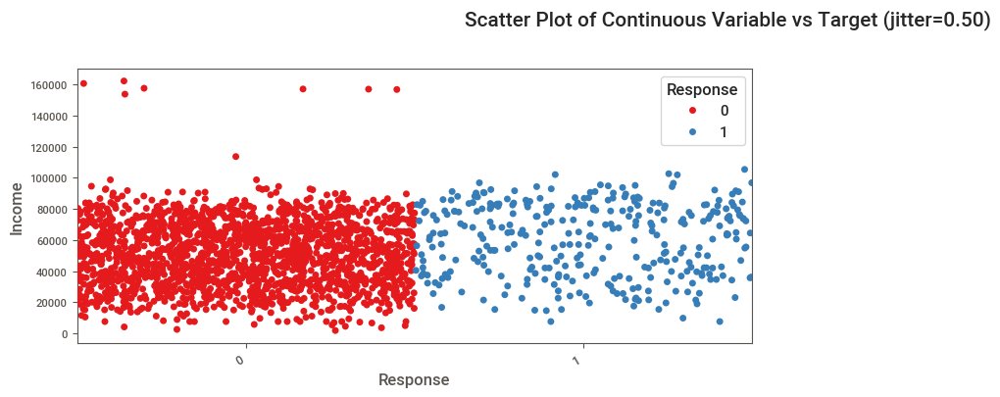

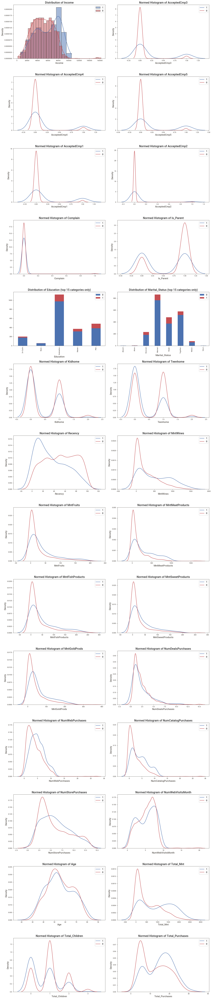

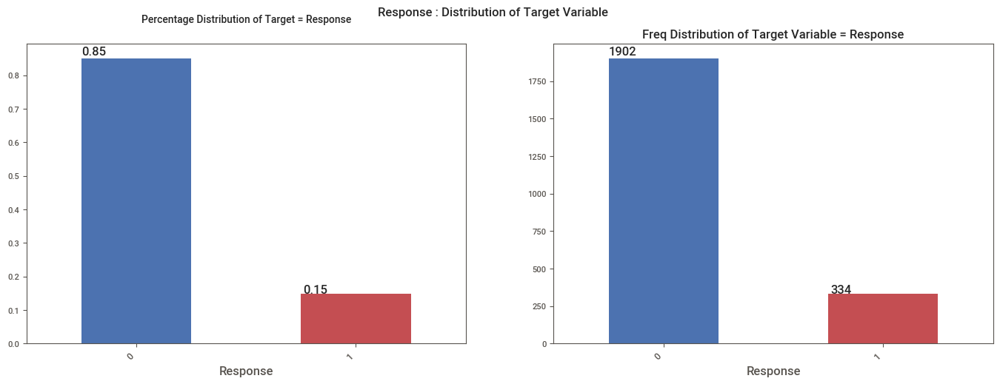

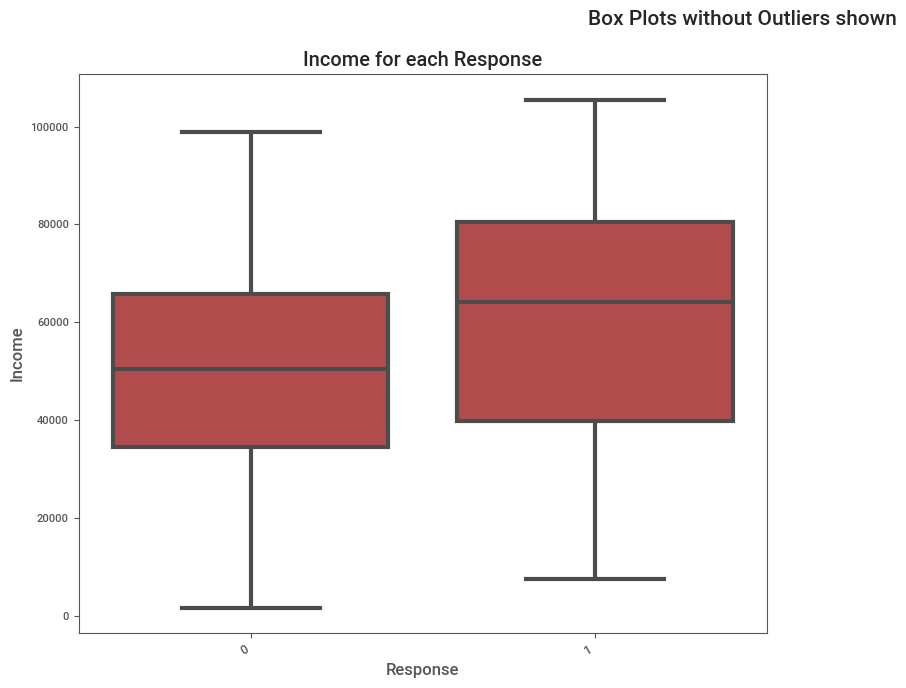

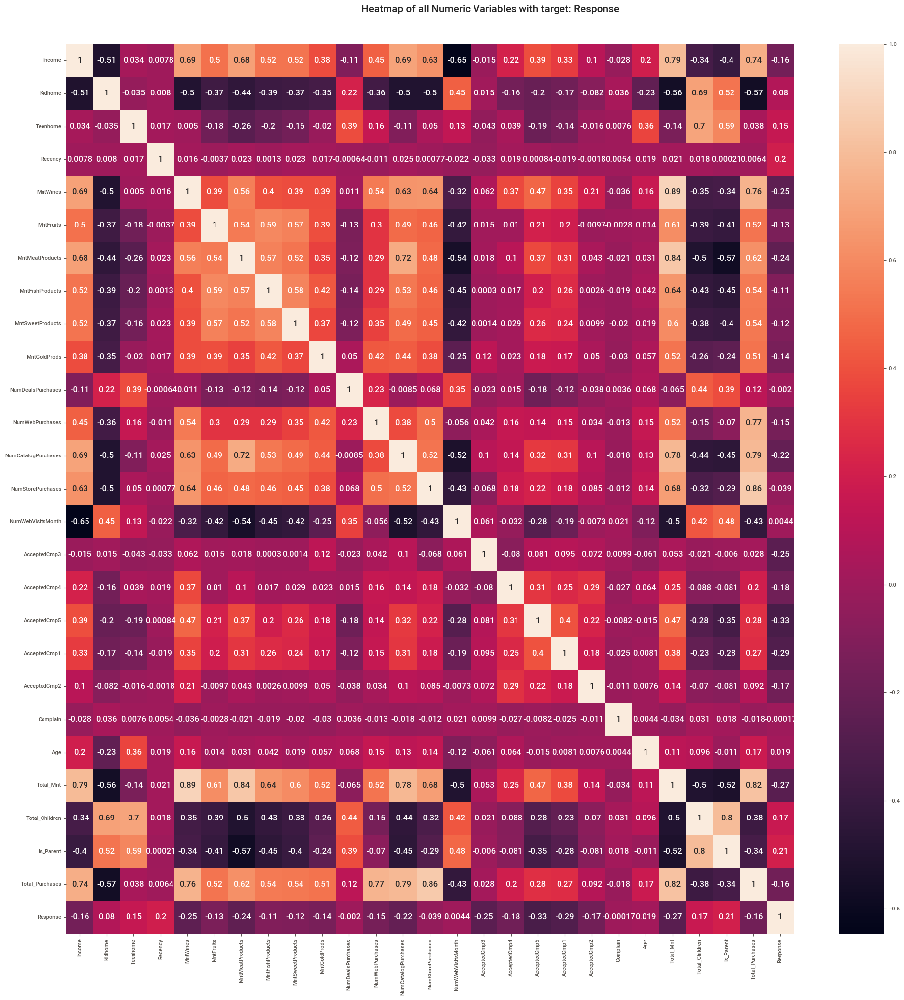

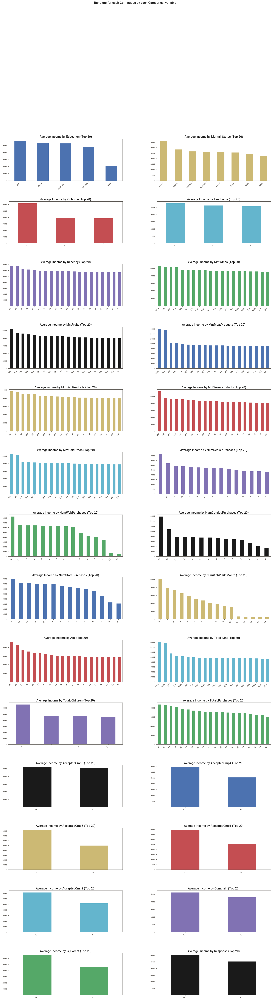

Could not draw wordcloud plot for Dt_Customer. We need at least 1 word to plot a word cloud, got 0.
All Plots done
Time to run AutoViz = 11 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package cmudict is already up-to-date!
[nltk_data]    | Downloading package gazetteers to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package gazetteers is already up-to-date!
[nltk_data]    | Downloading package genesis to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package genesis is already up-to-date!
[nltk_data]    | Downloading package gutenberg to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package gutenberg is already up-to-date!
[nltk_data]    | Downloading package inaugural to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package inaugural is already up-to-date!
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package movie_reviews is already up-to-date!
[nltk

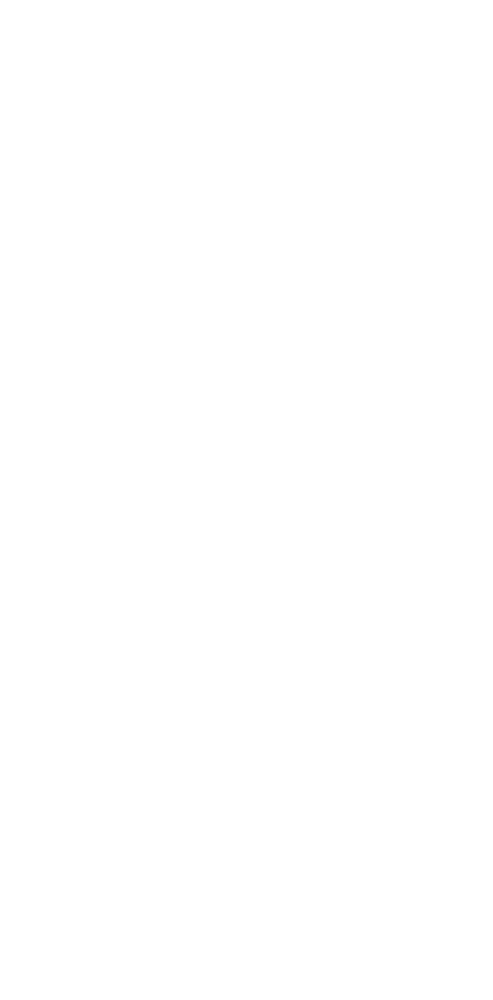

In [84]:
%matplotlib inline

dft = AV.AutoViz(
    filename="",                  
    sep=",",
    depVar="Response",            
    dfte=df_clean,                
    header=0,
    verbose=1,                   
    lowess=False,                 
    chart_format="svg",           
    max_rows_analyzed=150000,
    max_cols_analyzed=30
)

### Nhận xét :
- AutoViz tự động phân loại các biến trong dataset và tạo ra 5 nhóm biểu đồ chính:
  1. Pairwise Scatter Plots: biểu đồ tán xạ phân tích mối quan hệ giữa các biến số với biến mục tiêu Response.
  2. Distplots (Histograms + KDE): biểu đồ mật độ phân bố cho từng biến số độc lập.
  3. Violin Plots / Boxplots: phân tích sự phân tán và giá trị ngoại lai (Outliers) giữa biến số và biến phân loại.
  4. Bar Plots (Countplots): thống kê số lượng theo từng danh mục.
  5. Correlation Heatmap: ma trận nhiệt hiển thị hệ số tương quan giữa tất cả các cặp biến số.


## IV. PHÂN TÍCH CHUYÊN SÂU CÁC NHÓM BIỂU ĐỒ DO AUTOVIZ TẠO RA
Mục tiêu: trích xuất thông tin chi tiết từ từng nhóm biểu đồ đơn biến và hai biến do AutoViz tự động tạo ra.

### Trích xuất ma trận tương quan giữa các biến số chính với Response để kiểm chứng kết quả AutoViz


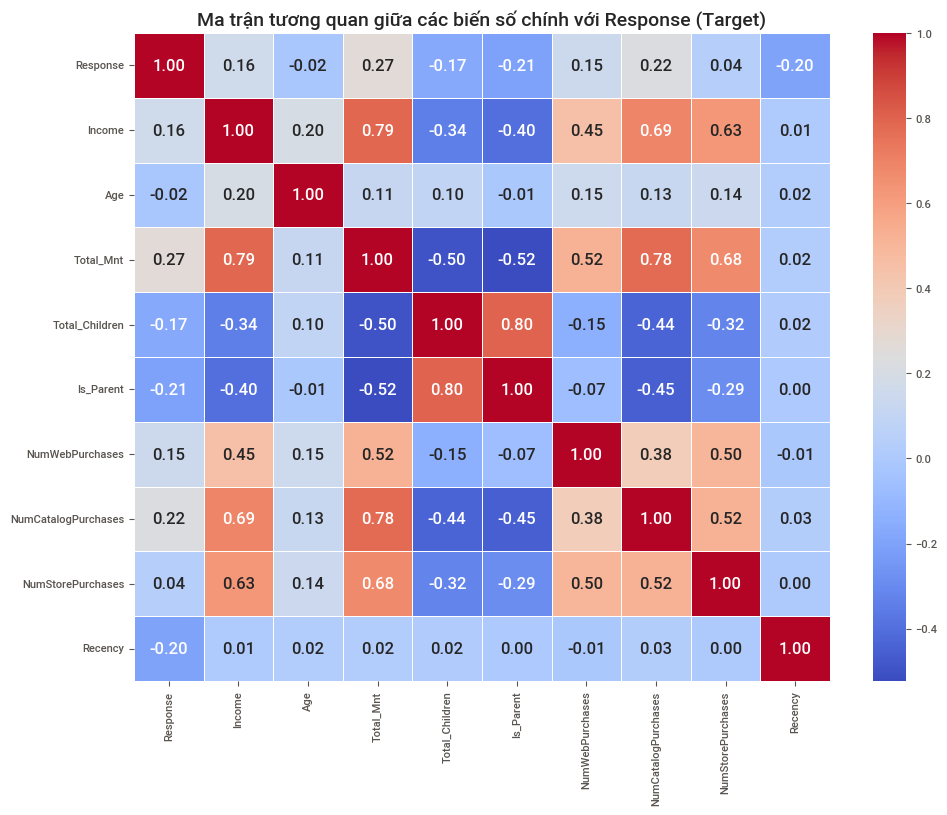

In [85]:
plt.figure(figsize=(10, 8))
selected_cols = ['Response', 'Income', 'Age', 'Total_Mnt', 'Total_Children', 'Is_Parent', 
                 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'Recency']

corr_matrix = df_clean[selected_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến số chính với Response (Target)', fontsize=14)
plt.show()

### Nhận xét & Insight :

1. Phân tích biểu đồ phân bố đơn biến (Distplots):
   - Income & Total_Mnt: phân bố lệch phải (Right-skewed) rõ rệt. Phần lớn khách hàng có thu nhập tập trung ở mức 30,000\\( - 70,000\\), chi tiêu phổ biến dưới 500\$.
   - Age: phân bố dạng chuẩn (Gaussian) lệch nhẹ, tập trung chủ yếu từ độ tuổi 40 đến 65.
>
2. Phân tích biểu đồ hai biến tương quan với Target (Response):
   - Tác động của Income & Total_Mnt: khách hàng chấp nhận chiến dịch tiếp thị (Response = 1) nằm ở vùng chi tiêu cao và thu nhập cao. Mối tương quan giữa Total_Mnt với Response đạt +0.27, thể hiện khách hàng VIP là nhóm dễ chuyển đổi nhất.
   - Tác động của Is_Parent & Total_Children: biểu đồ Bar plots của AutoViz thể hiện rõ sự tương quan âm (-0.18) giữa số lượng con cái và khả năng phản hồi chiến dịch. Khách hàng chưa có con (Is_Parent = 0) có tỷ lệ tham gia chiến dịch cao vượt trội.
   - Kênh bán hàng thành công nhất: kênh mua hàng qua Catalog (NumCatalogPurchases) có mối tương quan thuận cao nhất (+0.22) với Response.

### V. ĐỀ XUẤT CHIẾN LƯỢC KINH DOANH TỪ KẾT QUẢ AUTOVIZ
Mục tiêu: tổng hợp các insight rút ra từ biểu đồ AutoViz để đưa ra khuyến nghị kinh doanh cụ thể cho phòng Marketing.

### Trực quan hóa chi tiết mối quan hệ giữa kênh mua hàng với Response


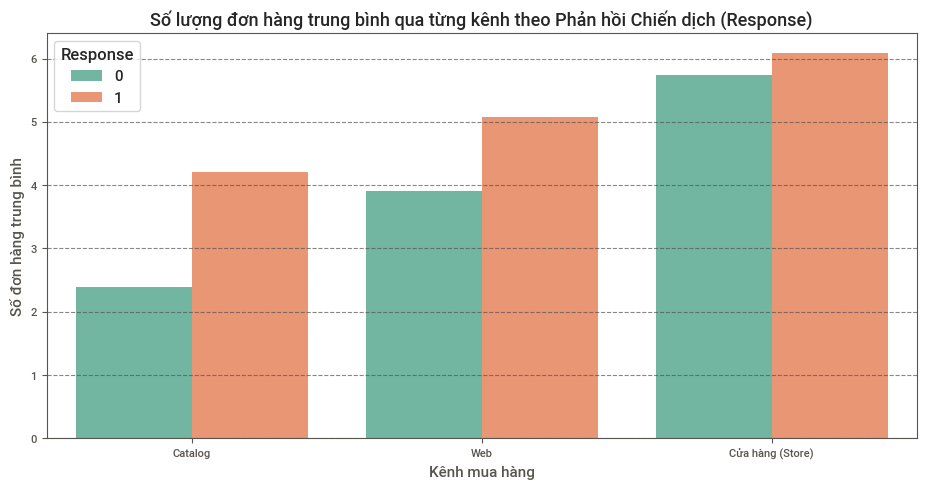

In [86]:
df_purchases = df_clean.groupby('Response')[['NumCatalogPurchases', 'NumWebPurchases', 'NumStorePurchases']].mean().reset_index()
df_purchases_melted = pd.melt(df_purchases, id_vars=['Response'], var_name='Purchase_Channel', value_name='Avg_Purchases')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_purchases_melted, x='Purchase_Channel', y='Avg_Purchases', hue='Response', palette='Set2')
plt.title('Số lượng đơn hàng trung bình qua từng kênh theo Phản hồi Chiến dịch (Response)', fontsize=13)
plt.xlabel('Kênh mua hàng', fontsize=11)
plt.ylabel('Số đơn hàng trung bình', fontsize=11)

plt.xticks(ticks=[0, 1, 2], labels=['Catalog', 'Web', 'Cửa hàng (Store)'])

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Khuyến nghị tiếp thị thực tiễn:
1. Tập trung phân khúc hhách hàng thu nhập cao & chưa có con:
   - Đây là nhóm có giá trị giỏ hàng (Total_Mnt) cao nhất và xác suất chấp nhận chiến dịch cao gấp 3 lần bình thường.
>
2. Tối ưu hóa kênh tiếp thị Catalog:
   - Biểu đồ AutoViz chỉ ra rằng khách hàng phản hồi chiến dịch (Response = 1) có số lượt mua hàng qua Catalog trung bình cao gấp hơn 2 lần so với nhóm Response = 0. Cần gia tăng ngân sách quảng cáo trực tiếp qua Catalog và Email tiếp thị cá nhân hóa.
>
3. Cải thiện tỷ lệ chuyển đổi kênh Web:
   - Khách hàng ghé thăm Website rất nhiều nhưng tỷ lệ chuyển đổi đơn hàng qua Web ở nhóm có con chưa cao. Cần thiết kế các chương trình khuyến mãi gia đình (Family Package) để kích cầu.

## VI. TỔNG KẾT BÀI THỰC HÀNH 2 (AUTOVIZ) & SO SÁNH TỔNG HỢP CÁC CÔNG CỤ EDA
Mục tiêu: đánh giá ưu/nhược điểm của AutoViz và đối chiếu với các công cụ SweetViz, ydata-profiling, D-Tale.

### In thống kê số lượng biểu đồ và thuộc tính đã được AutoViz phân tích tự động


In [87]:
print("BÁO CÁO TỔNG HỢP TIẾN TRÌNH AUTOVIZ")
print(f"- Tổng số bản ghi đã xử lý: {df_clean.shape} dòng")
print(f"- Tổng số đặc trưng đã phân tích: {df_clean.shape[1]} cột")
print(f"- Biến mục tiêu (Target Variable): 'Response'")
print("--> AutoViz đã tự động xuất ra toàn bộ hệ thống biểu đồ Matplotlib/Seaborn thành công.")

BÁO CÁO TỔNG HỢP TIẾN TRÌNH AUTOVIZ
- Tổng số bản ghi đã xử lý: (2236, 30) dòng
- Tổng số đặc trưng đã phân tích: 30 cột
- Biến mục tiêu (Target Variable): 'Response'
--> AutoViz đã tự động xuất ra toàn bộ hệ thống biểu đồ Matplotlib/Seaborn thành công.


## TỔNG KẾT BÀI THỰC HÀNH 2 (AUTOVIZ):

1. Về khả năng tự động hóa và trực quan hóa của AutoViz:
   - Tự động hóa hoàn toàn: chỉ với lệnh AV.AutoViz(), thư viện tự động nhận diện kiểu dữ liệu và sinh trọn vẹn các nhóm biểu đồ đơn biến & hai biến (Scatter plots, Distplots, Boxplots, Barplots, Correlation Heatmap).
   - Trực quan hóa Inline: các biểu đồ Matplotlib/Seaborn hiển thị trực tiếp ngay bên trong cell Kaggle Notebook, giúp kiểm tra kết quả nhanh chóng mà không cần mở file HTML riêng.
   - Hiệu năng xử lý: tốc độ tạo biểu đồ rất nhanh, tối ưu tốt cho tập dữ liệu lớn nhờ cơ chế tự động lấy mẫu (max_rows_analyzed).
>
2. Insight kinh doanh chính rút ra từ hệ thống biểu đồ AutoViz:
   - Phân khúc khách hàng tiềm năng: khách hàng có thu nhập cao (Income) và chưa có con (Is_Parent = 0) có tỷ lệ chấp nhận chiến dịch Marketing (Response = 1) cao gấp gần 3 lần nhóm có con.
   - Kênh bán hàng hiệu quả nhất: mua hàng qua Catalog (NumCatalogPurchases)** đóng vai trò quyết định với hệ số tương quan thuận cao nhất tới biến mục tiêu Response.
   - Mặt hàng chủ lực: chi tiêu cho rượu (MntWines) và thịt (MntMeatProducts) chiếm hơn 70% tổng giá trị giỏ hàng (Total_Mnt).

